DATA EXPLORATION
*************************************************************
Shape of the Data: (5045, 11)
First 10 Records:
       booking_id                             event_name headline_artist  \
0  IND-SHOW-30000  Magnetic Fields Festival Tour Edition    Arijit Singh   
1  IND-SHOW-30001     Hornbill Rock Contest Tour Edition  Shreya Ghoshal   
2  IND-SHOW-30002    Ziro Festival of Music Tour Edition         Nucleya   
3  IND-SHOW-30003             NH7 Weekender Tour Edition       Anuv Jain   
4  IND-SHOW-30004   Mahindra Blues Festival Tour Edition  Diljit Dosanjh   
5  IND-SHOW-30005     Hornbill Rock Contest Tour Edition  Diljit Dosanjh   
6  IND-SHOW-30006        Bangalore Open Air Tour Edition     A.R. Rahman   
7  IND-SHOW-30007        Lollapalooza India Tour Edition          Divine   
8  IND-SHOW-30008        Lollapalooza India Tour Edition       Anuv Jain   
9  IND-SHOW-30009        Lollapalooza India Tour Edition         Nucleya   

         music_genre         city   

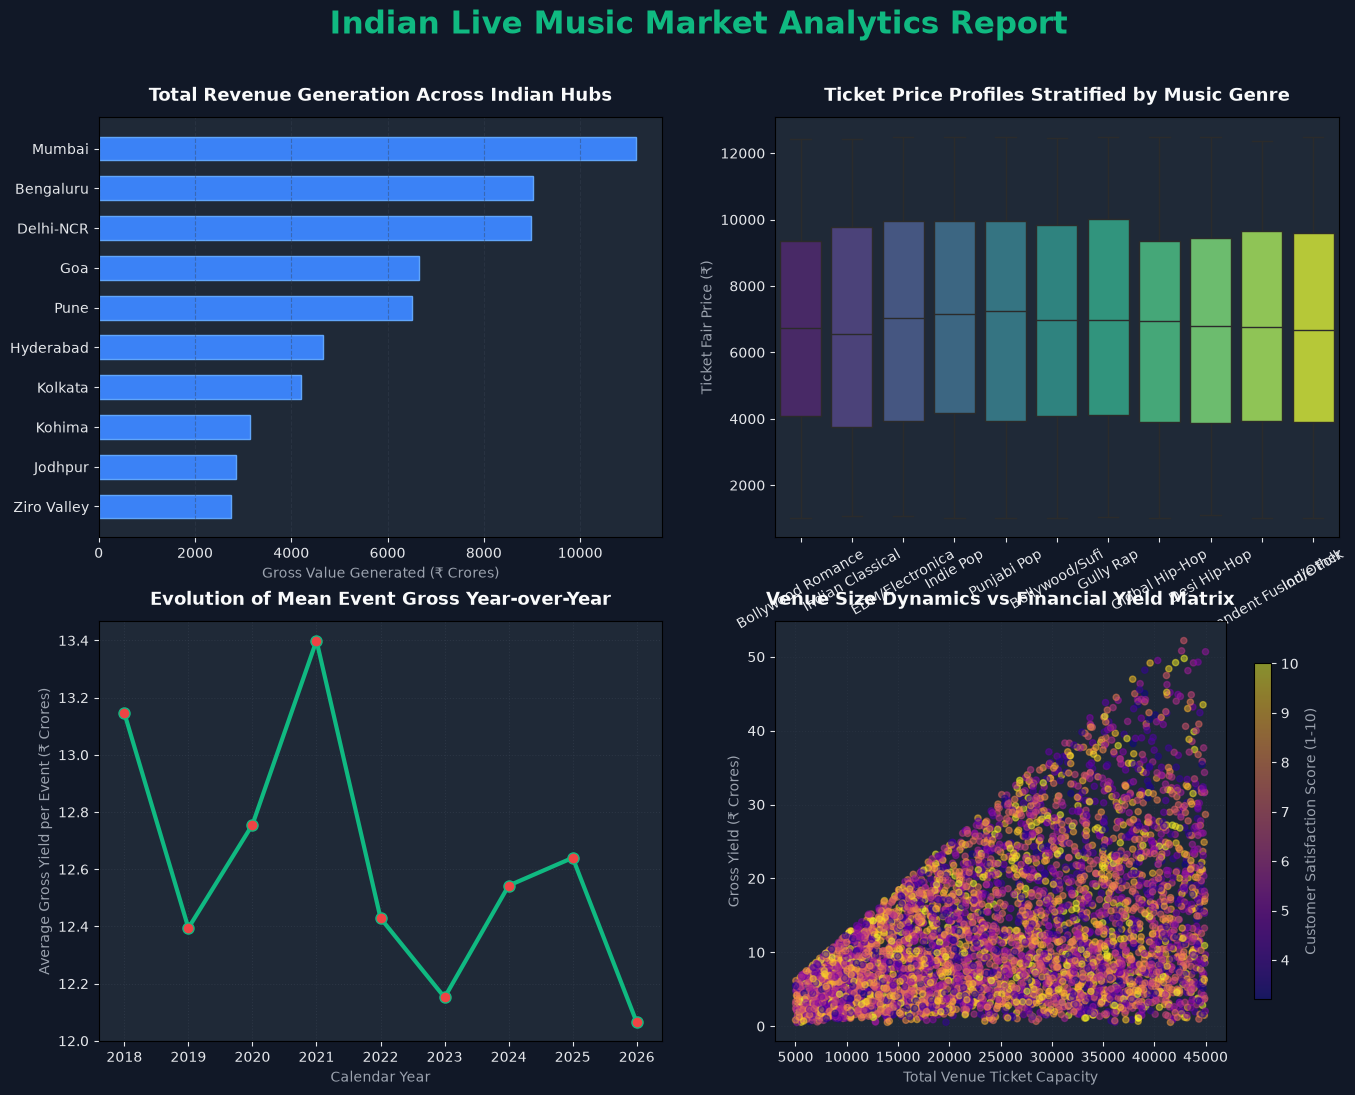

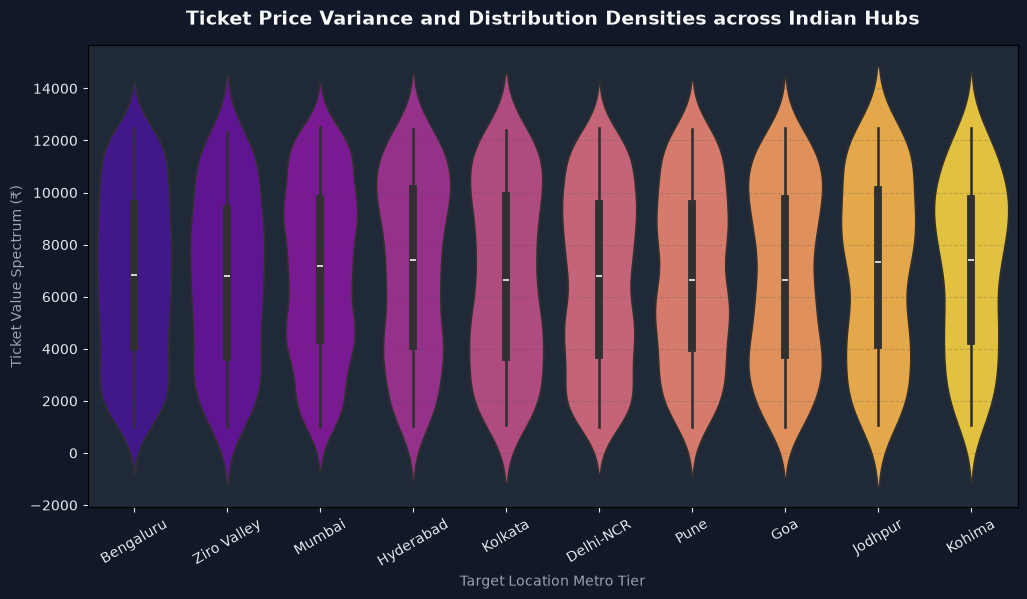

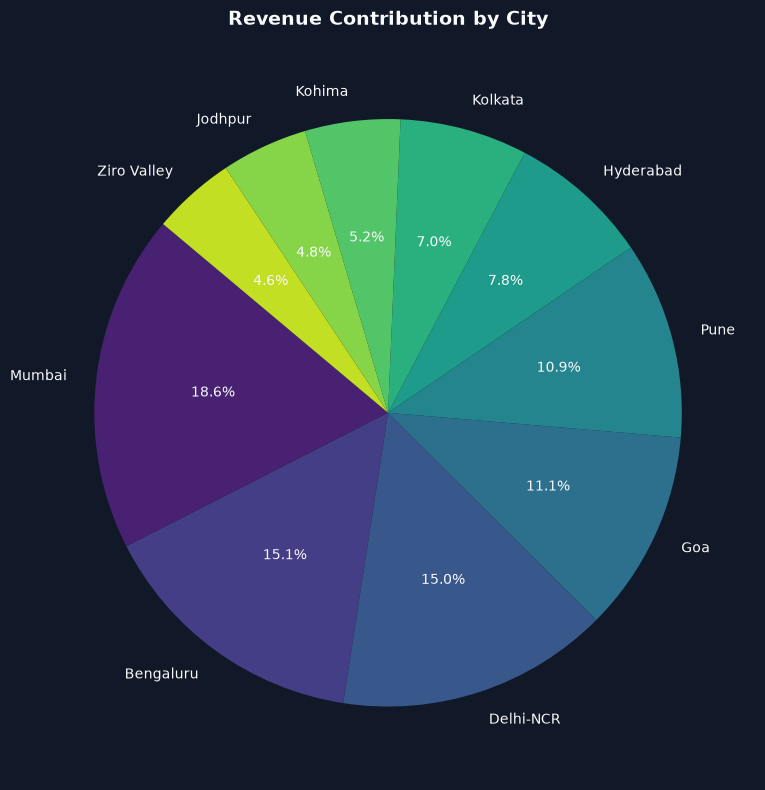

<Figure size 640x480 with 0 Axes>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# LOAD DATA
getdata = pd.read_csv("india_music_shows_dirty_5000.csv")
print("DATA EXPLORATION")
print("*************************************************************")
print(f"Shape of the Data: {getdata.shape}")
print("First 10 Records:")
print(getdata.head(10))
print("Last 10 Records")
print(getdata.tail(10))
print("DATA INFORMATION:")
print("---------------------------------------")
print(getdata.info())
print("Data Description:")
print("---------------------------------------")
print(getdata.describe())
print("Data Types")
print("---------------------------------------")
print(getdata.dtypes)
print("DATA CLEANING")
print("*************************************************************")

totalrows = len(getdata)
print(f"Total Number Of Rows: {totalrows}")
totalnullrows = getdata.isnull().sum()
print(f"Total Missing Values per Column:\n{totalnullrows}")
nullpercentage = (totalnullrows / totalrows) * 100
print(f"Percentage of Missing Values per Column:\n{nullpercentage}")

# DROPNA AND FILLNA
getdata = getdata.drop_duplicates()
getdata['music_genre'] = getdata['music_genre'].fillna("Independent Fusion/Other")
getdata['event_date'] = getdata['event_date'].str.replace("DATE_MISMATCH_", "", regex=False)
getdata['event_date'] = pd.to_datetime(getdata['event_date'], errors='coerce')
getdata = getdata.dropna(subset=['event_date'])
getdata['event_year'] = getdata['event_date'].dt.year

getdata = getdata[getdata['average_ticket_price_inr'] > 0]
getdata = getdata[getdata['customer_satisfaction_score'] > 0] 
getdata['tickets_sold'] = np.minimum(getdata['tickets_sold'], getdata['ticket_capacity'])
getdata['gross_revenue_crores'] = (getdata['tickets_sold'] * getdata['average_ticket_price_inr']) / 10_000_000

print(f"\n--- AFTER DROPNA AND FILLNA ---")
print(f"Total production records passing validation limits: {getdata.shape}\n")

# 3. ADVANCED VISUALIZATION CANVAS DESIGN
plt.rcParams['figure.facecolor'] = '#111827'
plt.rcParams['axes.facecolor'] = '#1F2937'
plt.rcParams['text.color'] = '#F9FAFB'
plt.rcParams['axes.labelcolor'] = '#9CA3AF'
plt.rcParams['xtick.color'] = '#E5E7EB'
plt.rcParams['ytick.color'] = '#E5E7EB'
plt.rcParams['grid.color'] = '#374151'

fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=100)
fig.suptitle("Indian Live Music Market Analytics Report", fontsize=22, fontweight='bold', color='#10B981', y=0.97)

# PANEL 1: Regional Demand Metrics
city_revenue = getdata.groupby('city')['gross_revenue_crores'].sum().sort_values()
axes[0, 0].barh(city_revenue.index, city_revenue.values, color='#3B82F6', edgecolor='#60A5FA', height=0.6)
axes[0, 0].set_title("Total Revenue Generation Across Indian Hubs", fontsize=13, weight='bold', pad=12)
axes[0, 0].set_xlabel("Gross Value Generated (₹ Crores)")
axes[0, 0].grid(axis='x', linestyle='--', alpha=0.4)

# PANEL 2: Pricing Dispersion Profiles 
sns.boxplot(ax=axes[0, 1], data=getdata, x='music_genre', y='average_ticket_price_inr', palette='viridis', hue='music_genre', legend=False)
axes[0, 1].set_title("Ticket Price Profiles Stratified by Music Genre", fontsize=13, weight='bold', pad=12)
axes[0, 1].set_xlabel("Genre Vertical")
axes[0, 1].set_ylabel("Ticket Fair Price (₹)")
axes[0, 1].tick_params(axis='x', rotation=30)

# PANEL 3: Time Series Scaling Waves 
yearly_gross = getdata.groupby('event_year')['gross_revenue_crores'].mean()
axes[1, 0].plot(yearly_gross.index, yearly_gross.values, marker='o', color='#10B981', linewidth=3, markersize=8, markerfacecolor='#EF4444')
axes[1, 0].set_title("Evolution of Mean Event Gross Year-over-Year", fontsize=13, weight='bold', pad=12)
axes[1, 0].set_xlabel("Calendar Year")
axes[1, 0].set_ylabel("Average Gross Yield per Event (₹ Crores)")
axes[1, 0].grid(True, linestyle=':', alpha=0.5)

# PANEL 4: Correlation Matrix Analysis 
scatter = axes[1, 1].scatter(getdata['ticket_capacity'], getdata['gross_revenue_crores'], c=getdata['customer_satisfaction_score'], cmap='plasma', alpha=0.5, s=20)
cbar = fig.colorbar(scatter, ax=axes[1, 1], orientation='vertical', shrink=0.8)
cbar.set_label('Customer Satisfaction Score (1-10)', color='#9CA3AF')
axes[1, 1].set_title("Venue Size Dynamics vs Financial Yield Matrix", fontsize=13, weight='bold', pad=12)
axes[1, 1].set_xlabel("Total Venue Ticket Capacity")
axes[1, 1].set_ylabel("Gross Yield (₹ Crores)")
axes[1, 1].grid(True, linestyle=':', alpha=0.3)

#violin 
fig4, ax4 = plt.subplots(figsize=(12, 6), dpi=100)
sns.violinplot(data=getdata, x='city', y='average_ticket_price_inr', palette='plasma', hue='city', legend=False, ax=ax4)
ax4.set_title("Ticket Price Variance and Distribution Densities across Indian Hubs", fontsize=14, fontweight='bold', pad=15)
ax4.set_xlabel("Target Location Metro Tier")
ax4.set_ylabel("Ticket Value Spectrum (₹)")
ax4.tick_params(axis='x', rotation=30)
ax4.grid(axis='y', linestyle='--', alpha=0.2)

#pie chart
city_revenue = getdata.groupby('city')['gross_revenue_crores'].sum().sort_values(ascending=False)
fig5, ax5 = plt.subplots(figsize=(8, 8), dpi=100)
ax5.pie(city_revenue.values, labels=city_revenue.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis', len(city_revenue)))
ax5.set_title("Revenue Contribution by City", fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig("chart4_ticket_distribution_violin.png", facecolor=fig4.get_facecolor())
plt.show()

plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig("india_music_shows_report.png", facecolor=fig.get_facecolor(), edgecolor='none')
plt.show()